## Difference between random and noise

First, let's get into one dimensional Perlin Noise. Let's imagine that, over time, we will choose a random number and write it down:

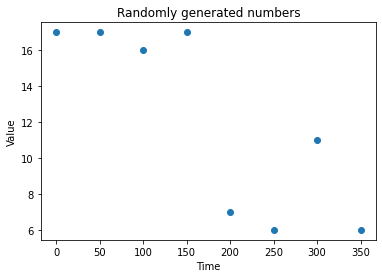

In [1]:
from random import randint

import matplotlib.pylab as plt

tamanho = 400
intervalo, amplitude = 50, 20

y = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x = [_ for _ in range(0, tamanho, intervalo)]

plt.title('Randomly generated numbers')
plt.ylabel('Value')
plt.xlabel('Time')

plt.scatter(x, y)
plt.show()

If we connect these points, we will have the following:

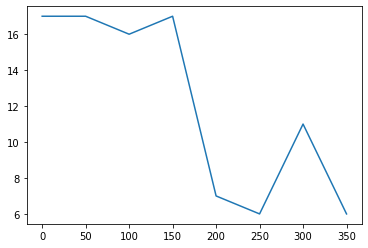

In [2]:
plt.plot(x, y)
plt.show()

As you can see, this graph does not look natural or organic when using linear interpolation to connect the points.
But how about the next one?

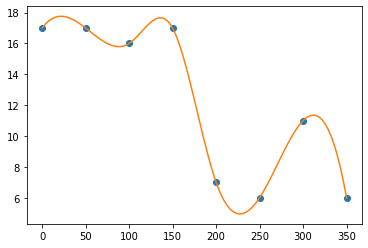

In [3]:
from scipy.interpolate import interp1d

import numpy as np

f = interp1d(x, y, kind='cubic')

x_new = np.linspace(0, x[-1], num=100, endpoint=True)
plt.plot(
    x, y, 'o',
    x_new, f(x_new), '-'
)
plt.show()

This smooth graph is plotting a matrix of one octave Perlin noise values. And what is this “octave”?

As we decrease by half the time interval and the amplitude for this randomness, we create a new octave.

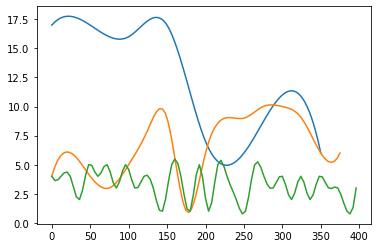

In [4]:
intervalo, amplitude = 25, 10

y2 = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x2 = [_ for _ in range(0, tamanho, intervalo)]

intervalo, amplitude = 12, 5

y3 = [randint(1, amplitude) for _ in range(0, tamanho, intervalo)]
x3 = [_ for _ in range(0, tamanho, intervalo)]

f2 = interp1d(x2, y2, kind='cubic')
f3 = interp1d(x3, y3, kind='cubic')

x_new2 = np.linspace(0, x2[-1], num=100, endpoint=True)
x_new3 = np.linspace(0, x3[-1], num=100, endpoint=True)

plt.plot(
    x_new, f(x_new), '-',
    x_new2, f2(x_new2), '-',
    x_new3, f3(x_new3), '-'
)
plt.show()

The overlapping of the octaves generates a one-dimensional set of Perlin noise values.

---

## Tests

[0.0, 0.014007575794820615, 0.028091115454189942, 0.042305908735860355, 0.05668652581642724, 0.07124877279624066, 0.08599157944814305, 0.10089881921003518, 0.11594106142126792, 0.13107725580286214, 0.14625634918155347, 0.1614188344576669, 0.17649823181681587, 0.19142250218543036, 0.20611539293010886, 0.22049771580080113, 0.23448855711781538, 0.2480064202026528, 0.2609703000526696, 0.2733006902595657, 0.28492052217170044, 0.29575603630023484, 0.3057375859691013, 0.3148003732088, 0.3228851168940232, 0.3299386531251033, 0.33591446785329326, 0.3407731617498688, 0.3444828473190602, 0.34701947825481044, 0.34836711104136037, 0.3485180987976606, 0.34747321736561115, 0.34524172364212663, 0.3418413461550298, 0.3372982078827709, 0.3316466813179749, 0.32492917577481506, 0.3171958569402138, 0.3085042986688704, 0.29891906702211524, 0.28851123655059185, 0.27735783882076526, 0.26554124318525735, 0.2531484697970095, 0.24027043486727154, 0.22700112816741894, 0.21343672277459497, 0.1996746170611814, 0.18

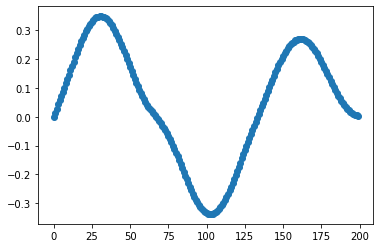

In [5]:
from perlin_noise import PerlinNoise

noise = PerlinNoise(octaves=3, seed=1234)

x_pix = 200

y = [noise(i / x_pix) for i in range(x_pix)]
x = [_ for _ in range(len(y))]

print(y)

plt.scatter(x, y)
plt.show()

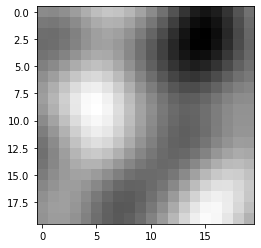

In [6]:
noise = PerlinNoise(octaves=2, seed=randint(1, 9999))
x_pix, y_pix = 20, 20
pic = [[noise([i/x_pix, j/y_pix]) for j in range(x_pix)] for i in range(y_pix)]

plt.imshow(pic, cmap='gray')
plt.show()